In [26]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [27]:
df = pd.read_csv("datasets/Social_Network_Ads.csv")

In [28]:
df

,Gender,Age,EstimatedSalary,Purchased
0,Male,19,19000,0
1,Male,35,20000,0
2,Female,26,43000,0
3,Female,27,57000,0
4,Male,19,76000,0
...,...,...,...,...
395,Female,46,41000,1
396,Male,51,23000,1
397,Female,50,20000,1
398,Male,36,33000,0


Train Test Split

In [29]:
df = df.drop("User ID", axis=1)

KeyError: "['User ID'] not found in axis"

In [ ]:
df.to_csv("datasets/Social_Network_Ads.csv", index=False)

In [ ]:
df

,Gender,Age,EstimatedSalary,Purchased
0,Male,19,19000,0
1,Male,35,20000,0
2,Female,26,43000,0
3,Female,27,57000,0
4,Male,19,76000,0
...,...,...,...,...
395,Female,46,41000,1
396,Male,51,23000,1
397,Female,50,20000,1
398,Male,36,33000,0


In [ ]:
df["Gender"] = df["Gender"].map({"Male" : 1, "Female" : 0})

In [ ]:
df

,Gender,Age,EstimatedSalary,Purchased
0,1,19,19000,0
1,1,35,20000,0
2,0,26,43000,0
3,0,27,57000,0
4,1,19,76000,0
...,...,...,...,...
395,0,46,41000,1
396,1,51,23000,1
397,0,50,20000,1
398,1,36,33000,0


Train Test Split

In [ ]:
from sklearn.model_selection import train_test_split

x =df.drop("Purchased", axis=1)
y =df["Purchased"]

In [ ]:
x_train, x_test ,y_train, y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [32]:
x_train

,Gender,Age,EstimatedSalary
3,0,27,57000
18,1,46,28000
202,0,39,134000
250,0,44,39000
274,0,57,26000
...,...,...,...
71,0,24,27000
106,0,26,35000
270,0,43,133000
348,1,39,77000


Appling Standard Scaler

In [ ]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

In [ ]:
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [ ]:
x_test_scaled

array([[-1.        ,  0.79753468, -1.40447546],
       [-1.        ,  2.07309956,  0.51542886],
       [-1.        , -0.96863208, -0.76450736],
       [-1.        ,  0.99377543,  0.74814454],
       [-1.        , -0.87051171, -1.22993871],
       [-1.        , -0.77239133, -0.24089709],
       [-1.        ,  0.89565505,  1.06812859],
       [-1.        , -0.87051171,  0.36998156],
       [ 1.        ,  0.20881242,  0.13726589],
       [ 1.        ,  0.40505317, -0.15362871],
       [-1.        , -0.28178945, -0.15362871],
       [-1.        ,  1.4843773 , -1.05540195],
       [-1.        , -1.45923396, -0.64814952],
       [-1.        , -1.75359508, -1.37538601],
       [ 1.        , -0.77239133,  0.4863394 ],
       [ 1.        , -0.28178945,  1.09721805],
       [-1.        ,  1.38625693, -0.93904411],
       [-1.        ,  0.79753468,  0.10817643],
       [ 1.        ,  0.11069205, -0.82268628],
       [ 1.        ,  1.77873843, -0.29907601],
       [-1.        , -1.55735433, -1.259

In [30]:
x_train_scaled = pd.DataFrame(data =x_train_scaled, columns=x_train.columns)
x_test_scaled = pd.DataFrame(data =x_test_scaled, columns=x_test.columns)

In [31]:
x_train_scaled

,Gender,Age,EstimatedSalary
0,-1.0,-1.066752,-0.386344
1,1.0,0.797535,-1.229939
2,-1.0,0.110692,1.853544
3,-1.0,0.601294,-0.909955
4,-1.0,1.876859,-1.288118
...,...,...,...
315,-1.0,-1.361114,-1.259028
316,-1.0,-1.164873,-1.026312
317,-1.0,0.503174,1.824455
318,1.0,0.110692,0.195445


In [39]:
np.round(x_train.describe(),2)

,Gender,Age,EstimatedSalary
count,320.0,320.00,320.00
mean,0.5,37.87,70281.25
std,0.5,10.21,34430.55
min,0.0,18.00,15000.00
25%,0.0,30.00,43000.00
50%,0.5,37.00,71000.00
75%,1.0,45.00,88000.00
max,1.0,60.00,150000.00


In [40]:
np.round(x_train_scaled.describe(),2)

,Gender,Age,EstimatedSalary
count,320.0,320.00,320.00
mean,0.0,-0.00,0.00
std,1.0,1.00,1.00
min,-1.0,-1.95,-1.61
25%,-1.0,-0.77,-0.79
50%,0.0,-0.09,0.02
75%,1.0,0.70,0.52
max,1.0,2.17,2.32


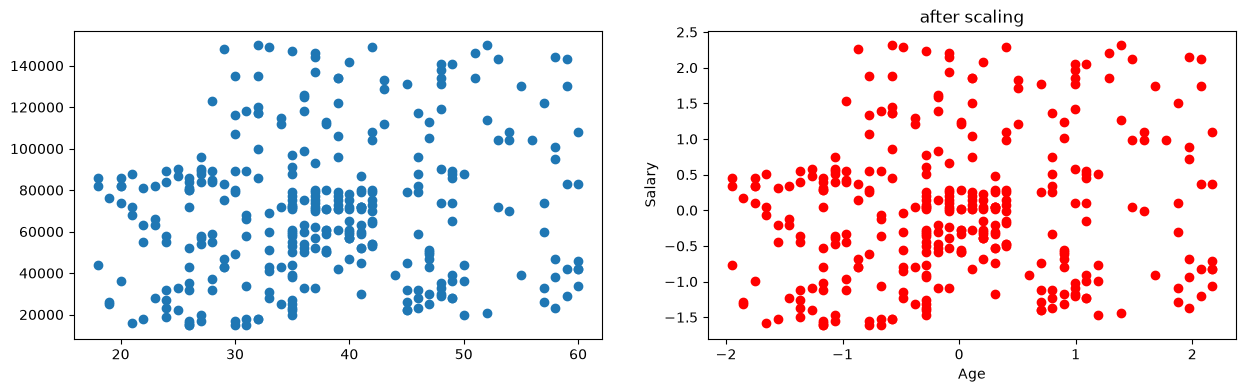

In [43]:
fig,(x1,x2) = plt.subplots(1,2,figsize=(15,4))
x1.scatter(x_train['Age'],x_train['EstimatedSalary'])
plt.title("before")



x2.scatter(x_train_scaled['Age'],x_train_scaled['EstimatedSalary'],color='red')
plt.title('after scaling')
plt.xlabel("Age")
plt.ylabel('Salary')
plt.show()